# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [1]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import time

start_total_time = time.time()
phase1_start = time.time()

# 1. Connect to 'enterprise_database.db'
conn = sqlite3.connect('enterprise_database.db')

# 2. Write a SQL query (using Window Functions) to isolate the most
#    recent chronological update for each unique user.
# 3. Only keep users whose latest status is 'Active'.
sql_query = """
WITH RankedUsers AS (
    SELECT 
        user_id, 
        name, 
        status, 
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id 
            ORDER BY updated_at DESC
        ) AS row_num
    FROM users
)
SELECT 
    user_id, 
    name, 
    status, 
    updated_at
FROM RankedUsers
WHERE row_num = 1 
  AND status = 'Active';
"""

# 4. Load the result into a Pandas DataFrame called 'df_active_users'.
df_active_users = pd.read_sql_query(sql_query, conn)
conn.close()

phase1_duration = time.time() - phase1_start
print(f"Phase 1 execution time: {phase1_duration:.4f} seconds")
print(f"Total Active Users extracted: {len(df_active_users):,}")
print("\nFirst 5 records of df_active_users:")
print(df_active_users.head())


Phase 1 execution time: 0.1176 seconds
Total Active Users extracted: 14,183

First 5 records of df_active_users:
   user_id          name  status           updated_at
0  U-00001  User_U-00001  Active  2023-01-28 14:00:00
1  U-00003  User_U-00003  Active  2023-01-22 14:00:00
2  U-00005  User_U-00005  Active  2023-01-17 14:00:00
3  U-00006  User_U-00006  Active  2023-01-05 14:00:00
4  U-00007  User_U-00007  Active  2023-01-27 14:00:00


In [2]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================
phase2_start = time.time()

# 1. Load 'server_logs.txt' into a DataFrame (Vectorized)
df_raw_logs = pd.read_csv('server_logs.txt')
total_raw = len(df_raw_logs)
print(f"Total raw log records loaded: {total_raw:,}")

# 2. Drop any rows where the log contains the word 'ERROR'
log_col = df_raw_logs.columns[0]
df_clean_logs = df_raw_logs[~df_raw_logs[log_col].str.contains("ERROR", regex=False, na=False)].copy()
dropped_count = total_raw - len(df_clean_logs)
print(f"Dropped corrupted error logs: {dropped_count:,}")
print(f"Remaining valid logs: {len(df_clean_logs):,}")

# 3. Use Pandas string methods (.str.extract()) with Regular Expressions
#    to extract Date, User ID, Product ID, and Euro Value from the payload.
regex_pattern = r'\[(\d{4}-\d{2}-\d{2}).*?\].*?"u":"?([A-Za-z0-9_-]+)"?.*?"item_code":"?([A-Za-z0-9_-]+)"?.*?"eur_val":\s*([0-9.]+)'

extracted_data = df_clean_logs[log_col].str.extract(regex_pattern)
extracted_data.columns = ['Date', 'user_id', 'product_id', 'eur_val']

# 4. Cast numeric column 'eur_val' to float for mathematical calculations
extracted_data['eur_val'] = pd.to_numeric(extracted_data['eur_val'])

phase2_duration = time.time() - phase2_start
print(f"Phase 2 execution time: {phase2_duration:.4f} seconds")
print(f"Parsed records in 'extracted_data': {len(extracted_data):,}")
print(f"Missing values check:\n{extracted_data.isnull().sum().to_dict()}")
print("\nFirst 5 records of extracted_data:")
print(extracted_data.head())


Total raw log records loaded: 100,000
Dropped corrupted error logs: 5,098
Remaining valid logs: 94,902
Phase 2 execution time: 0.3200 seconds
Parsed records in 'extracted_data': 94,902
Missing values check:
{'Date': 0, 'user_id': 0, 'product_id': 0, 'eur_val': 0}

First 5 records of extracted_data:
         Date  user_id product_id  eur_val
0  2023-03-15  U-19484    PRD-874  3404.44
2  2023-05-09  U-18932    PRD-905  3406.21
3  2023-10-21  U-15882    PRD-284   164.08
4  2023-01-10  U-22781    PRD-665    26.80
5  2023-05-23  U-13348    PRD-589  4964.77


In [3]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================
phase3_start = time.time()

# 1. Load 'daily_exchange_rates.csv' into a DataFrame.
df_exchange_rates = pd.read_csv('daily_exchange_rates.csv')
missing_before = df_exchange_rates['EUR_to_USD'].isnull().sum()
print(f"Missing weekend exchange rates before forward-fill: {missing_before}")

# 2. Handle missing weekend data using .ffill() so Friday's rate rolls over to Saturday & Sunday
df_exchange_rates['Date'] = pd.to_datetime(df_exchange_rates['Date'])
df_exchange_rates = df_exchange_rates.sort_values('Date').reset_index(drop=True)
df_exchange_rates['EUR_to_USD'] = df_exchange_rates['EUR_to_USD'].ffill()
df_exchange_rates['Date'] = df_exchange_rates['Date'].dt.strftime('%Y-%m-%d')
missing_after = df_exchange_rates['EUR_to_USD'].isnull().sum()
print(f"Missing exchange rates after forward-fill: {missing_after}")

# 3. Merge cleaned logs with exchange rates by Date
df_reconciled = pd.merge(extracted_data, df_exchange_rates, on='Date', how='inner')
print(f"Cleaned logs merged with daily exchange rates: {len(df_reconciled):,} rows")

# 4. Merge that result with active SQL users by user_id
df_final = pd.merge(df_reconciled, df_active_users, on='user_id', how='inner')
print(f"Transactions belonging to currently Active users: {len(df_final):,} rows")

# 5. Calculate a new column called 'USD_Revenue' (Euro Value * Exchange Rate)
df_final['USD_Revenue'] = df_final['eur_val'] * df_final['EUR_to_USD']

phase3_duration = time.time() - phase3_start
print(f"Phase 3 execution time: {phase3_duration:.4f} seconds")
print(f"Total Reconciled USD Revenue: ${df_final['USD_Revenue'].sum():,.2f}")
print("\nFirst 5 records of df_final:")
print(df_final[['Date', 'user_id', 'name', 'product_id', 'eur_val', 'EUR_to_USD', 'USD_Revenue']].head())


Missing weekend exchange rates before forward-fill: 104
Missing exchange rates after forward-fill: 0
Cleaned logs merged with daily exchange rates: 94,902 rows
Transactions belonging to currently Active users: 53,899 rows
Phase 3 execution time: 0.0631 seconds
Total Reconciled USD Revenue: $148,274,622.91

First 5 records of df_final:
         Date  user_id          name product_id  eur_val  EUR_to_USD  USD_Revenue
0  2023-03-15  U-19484  User_U-19484    PRD-874  3404.44    1.178232  4011.220772
1  2023-10-21  U-15882  User_U-15882    PRD-284   164.08    1.075350   176.443420
2  2023-01-10  U-22781  User_U-22781    PRD-665    26.80    1.127128    30.207030
3  2023-10-20  U-22062  User_U-22062    PRD-363    48.63    1.075350    52.294268
4  2023-12-02  U-22146  User_U-22146    PRD-223   960.60    1.066142  1024.135923


=== Monthly Revenue Summary ===
Month: 2023-01 -> USD Revenue: $12,841,761.38
Month: 2023-02 -> USD Revenue: $11,436,130.90
Month: 2023-03 -> USD Revenue: $12,348,931.84
Month: 2023-04 -> USD Revenue: $12,015,376.19
Month: 2023-05 -> USD Revenue: $12,333,644.45
Month: 2023-06 -> USD Revenue: $12,084,355.82
Month: 2023-07 -> USD Revenue: $12,444,163.58
Month: 2023-08 -> USD Revenue: $12,812,730.66
Month: 2023-09 -> USD Revenue: $12,228,952.05
Month: 2023-10 -> USD Revenue: $12,501,330.36
Month: 2023-11 -> USD Revenue: $12,588,223.09
Month: 2023-12 -> USD Revenue: $12,639,022.60

=== Top 5 Most Valuable Customers ===
1. User_U-06582 (U-06582) -> USD Revenue: $40,050.99
2. User_U-23313 (U-23313) -> USD Revenue: $39,555.81
3. User_U-03805 (U-03805) -> USD Revenue: $39,529.95
4. User_U-20018 (U-20018) -> USD Revenue: $38,649.97
5. User_U-06489 (U-06489) -> USD Revenue: $38,629.14

[EXPORT COMPLETE] Clean dataset exported to 'power_bi_ready_dataset.csv' (53,899 rows).
[PIPELINE SLA PASSED] T

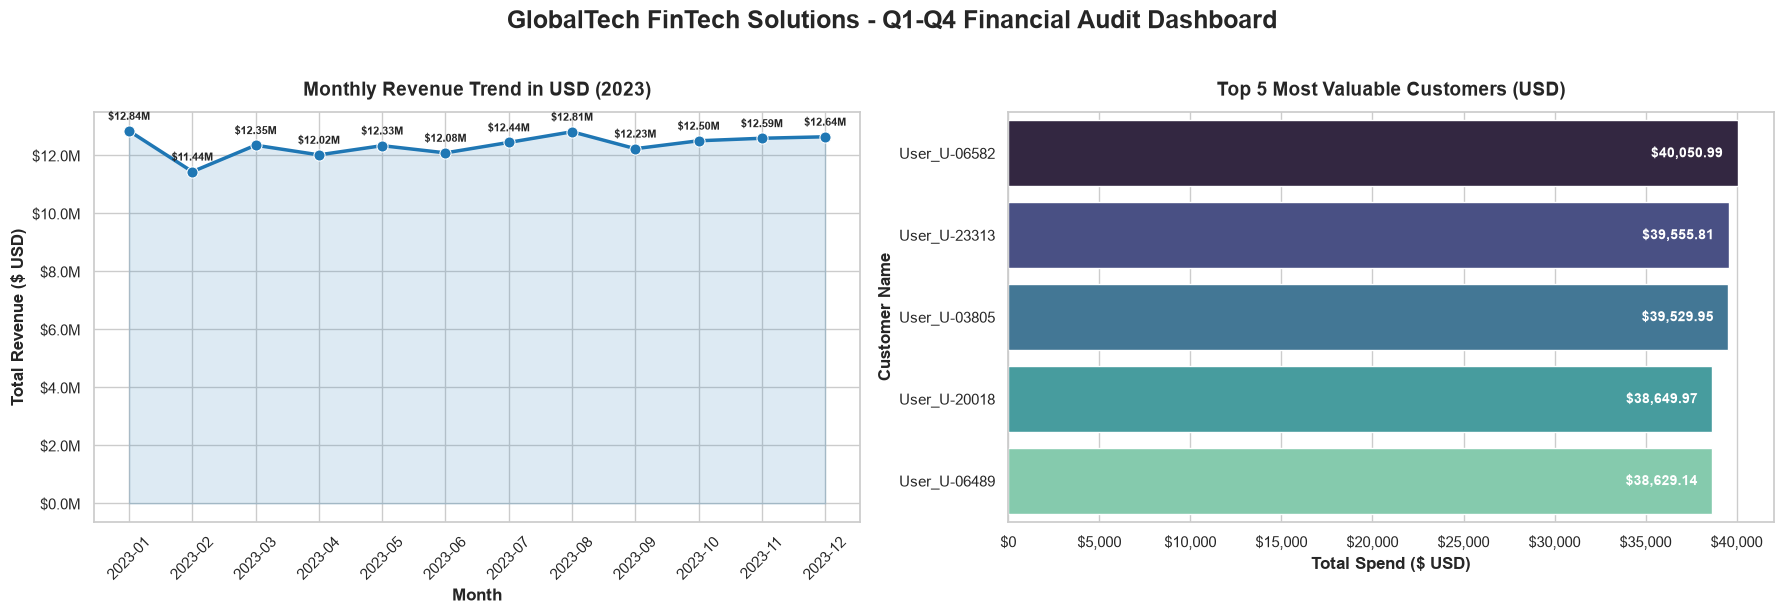

In [4]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================
import matplotlib.ticker as ticker

phase4_start = time.time()

# 1. Group data in 'df_final' to calculate Total USD Revenue by Month
df_final['Month'] = pd.to_datetime(df_final['Date']).dt.to_period('M').astype(str)
monthly_revenue = df_final.groupby('Month')['USD_Revenue'].sum().reset_index()

# 2. Group data to find Top 5 Most Valuable Customers by Total USD spent
customer_revenue = df_final.groupby(['user_id', 'name'])['USD_Revenue'].sum().reset_index()
top_5_customers = customer_revenue.sort_values(by='USD_Revenue', ascending=False).head(5).reset_index(drop=True)

print("=== Monthly Revenue Summary ===")
for _, row in monthly_revenue.iterrows():
    print(f"Month: {row['Month']} -> USD Revenue: ${row['USD_Revenue']:,.2f}")

print("\n=== Top 5 Most Valuable Customers ===")
for i, row in top_5_customers.iterrows():
    print(f"{i+1}. {row['name']} ({row['user_id']}) -> USD Revenue: ${row['USD_Revenue']:,.2f}")

# 3. Use Matplotlib & Seaborn to generate two charts side-by-side
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6), dpi=100)
fig.suptitle('GlobalTech FinTech Solutions - Q1-Q4 Financial Audit Dashboard', fontsize=18, fontweight='bold', y=1.02)

# Chart 1: Revenue Trends Over Time (Monthly Revenue)
ax1 = axes[0]
sns.lineplot(
    data=monthly_revenue, 
    x='Month', 
    y='USD_Revenue', 
    marker='o', 
    markersize=8, 
    linewidth=2.5, 
    color='#1f77b4', 
    ax=ax1
)
ax1.set_title('Monthly Revenue Trend in USD (2023)', fontsize=14, fontweight='bold', pad=12)
ax1.set_xlabel('Month', fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Revenue ($ USD)', fontsize=12, fontweight='bold')
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"${x*1e-6:.1f}M"))
ax1.tick_params(axis='x', rotation=45)
ax1.fill_between(monthly_revenue['Month'], monthly_revenue['USD_Revenue'], color='#1f77b4', alpha=0.15)
for _, row in monthly_revenue.iterrows():
    ax1.annotate(f"${row['USD_Revenue']*1e-6:.2f}M", 
                 (row['Month'], row['USD_Revenue']),
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8, fontweight='bold')

# Chart 2: Top 5 Customers by Revenue
ax2 = axes[1]
palette = sns.color_palette("mako", n_colors=5)
sns.barplot(
    data=top_5_customers, 
    x='USD_Revenue', 
    y='name', 
    hue='name',
    legend=False,
    palette=palette, 
    ax=ax2
)
ax2.set_title('Top 5 Most Valuable Customers (USD)', fontsize=14, fontweight='bold', pad=12)
ax2.set_xlabel('Total Spend ($ USD)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Customer Name', fontsize=12, fontweight='bold')
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"${x:,.0f}"))
for i, row in top_5_customers.iterrows():
    ax2.text(row['USD_Revenue'] * 0.98, i, f" ${row['USD_Revenue']:,.2f}", 
             ha='right', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# ===================================================================
# PHASE 5: BI HANDOFF
# ===================================================================
output_csv = 'power_bi_ready_dataset.csv'
df_final.to_csv(output_csv, index=False)
print(f"\n[EXPORT COMPLETE] Clean dataset exported to '{output_csv}' ({len(df_final):,} rows).")

total_pipeline_time = time.time() - start_total_time
print(f"[PIPELINE SLA PASSED] Total execution time: {total_pipeline_time:.2f} seconds (Limit: < 120s)")
